# Урок 4. Линейная регрессия

Работа состоит из трёх частей: теория своими словами, регрессия на баллах
студентов и собственная задача регрессии на ценах автомобилей.

## Часть 1. Теория

**Регрессия** — задача предсказания непрерывного числа: цены, балла, веса.
В отличие от выбора из категорий, ответом служит любое значение на шкале.

**Линейная регрессия** — модель, которая ищет прямую (в многомерном случае —
плоскость), наилучшим образом описывающую связь признаков с целевой переменной.
Предсказание считается как сумма признаков, умноженных на веса, плюс свободный член.

**Чем регрессия отличается от классификации.** Регрессия отвечает «сколько»,
классификация — «какой класс». Предсказать балл 78.4 — регрессия, предсказать
«сдал / не сдал» — классификация.

**Признаки** — входные характеристики объекта, на основе которых делается
предсказание: часы подготовки, посещаемость, число домашних работ.

**Целевая переменная** — то, что модель должна предсказать. Здесь это `score`.

**Обучение модели** — подбор весов так, чтобы ошибка на обучающих данных
стала минимальной.

**Предсказание модели** — применение подобранных весов к новым данным.

**Ошибка модели** — разница между настоящим значением и предсказанным.

**MAE** — средняя абсолютная ошибка, среднее значение модулей отклонений.
Измеряется в тех же единицах, что и target, поэтому понятнее всего для человека.

**MSE** — средний квадрат ошибки. Возводит отклонения в квадрат, поэтому сильно
штрафует крупные промахи.

**RMSE** — корень из MSE. Возвращает величину в исходные единицы, но остаётся
чувствительным к выбросам.

**R²** — доля дисперсии целевой переменной, объяснённая моделью. Единица означает
идеальное попадание, ноль — модель не лучше среднего значения.

**coef_** — веса признаков. Показывают, на сколько изменится предсказание при
росте признака на единицу.

**intercept_** — свободный член, предсказание при нулевых значениях всех признаков.

**Почему важно делить данные на train и test.** Модель легко запоминает те данные,
на которых училась. Честная оценка качества возможна только на примерах, которых
модель не видела.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)

## Часть 2. Баллы студентов

### Создание датасета

In [2]:
students = pd.DataFrame({
    "hours": [2, 5, 1, 8, 6, 10, 3, 7, 4, 9, 2, 6, 11, 5, 8, 1, 7, 10, 3, 9],
    "attendance": [55, 78, 42, 95, 83, 98, 60, 88, 70, 92, 48, 80, 100, 75, 90, 40, 85, 96, 62, 94],
    "homework_count": [2, 5, 1, 9, 6, 10, 3, 8, 4, 9, 2, 6, 10, 5, 8, 1, 7, 10, 3, 9],
    "score": [48, 67, 38, 92, 76, 97, 54, 84, 63, 90, 44, 73, 99, 69, 88, 35, 80, 95, 57, 91],
})
students

,hours,attendance,homework_count,score
0,2,55,2,48
1,5,78,5,67
2,1,42,1,38
3,8,95,9,92
4,6,83,6,76
5,10,98,10,97
6,3,60,3,54
7,7,88,8,84
8,4,70,4,63
9,9,92,9,90


In [3]:
students.head()

,hours,attendance,homework_count,score
0,2,55,2,48
1,5,78,5,67
2,1,42,1,38
3,8,95,9,92
4,6,83,6,76


In [4]:
students.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   hours           20 non-null     int64
 1   attendance      20 non-null     int64
 2   homework_count  20 non-null     int64
 3   score           20 non-null     int64
dtypes: int64(4)
memory usage: 772.0 bytes


In [5]:
students.describe()

,hours,attendance,homework_count,score
count,20.000000,20.000000,20.000000,20.000000
mean,5.850000,76.550000,5.900000,72.000000
std,3.166851,19.264024,3.160613,20.517002
min,1.000000,40.000000,1.000000,35.000000
25%,3.000000,61.500000,3.000000,56.250000
50%,6.000000,81.500000,6.000000,74.500000
75%,8.250000,92.500000,9.000000,90.250000
max,11.000000,100.000000,10.000000,99.000000


### График: связь часов подготовки и итогового балла

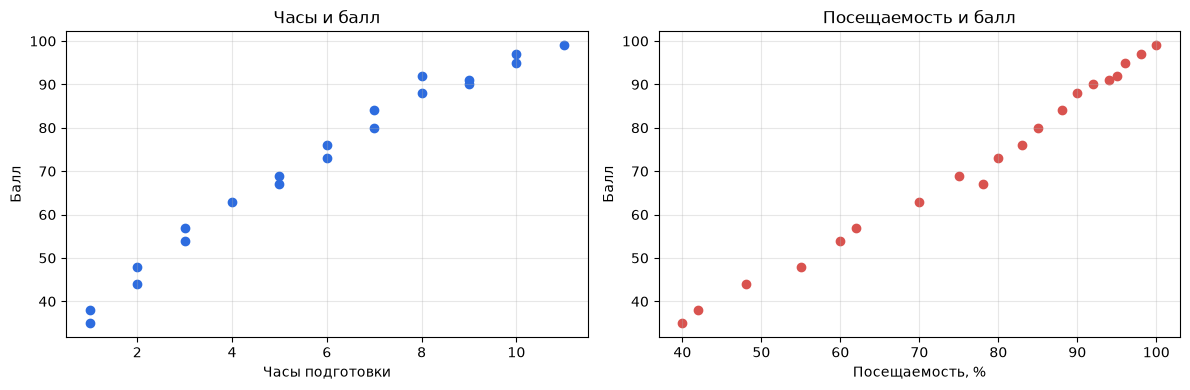

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(students["hours"], students["score"], color="#2d6cdf")
axes[0].set_xlabel("Часы подготовки")
axes[0].set_ylabel("Балл")
axes[0].set_title("Часы и балл")
axes[0].grid(alpha=0.3)

axes[1].scatter(students["attendance"], students["score"], color="#d9534f")
axes[1].set_xlabel("Посещаемость, %")
axes[1].set_ylabel("Балл")
axes[1].set_title("Посещаемость и балл")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Признаки, целевая переменная и разделение выборки

In [7]:
X = students[["hours", "attendance", "homework_count"]]
y = students["score"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)

Обучающая выборка: (16, 3)
Тестовая выборка: (4, 3)


### Обучение и предсказание

In [8]:
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    "real_score": y_test.values,
    "predicted_score": y_pred.round(2),
})
comparison["error"] = (comparison["real_score"] - comparison["predicted_score"]).round(2)
comparison["abs_error"] = comparison["error"].abs()
comparison

,real_score,predicted_score,error,abs_error
0,48,48.45,-0.45,0.45
1,95,95.61,-0.61,0.61
2,35,36.73,-1.73,1.73
3,67,70.63,-3.63,3.63


### Метрики

In [9]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.2f}")
print(f"MSE:  {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R2:   {r2:.4f}")

MAE:  1.60
MSE:  4.18
RMSE: 2.04
R2:   0.9918


### Коэффициенты модели

In [10]:
coefficients = pd.DataFrame({
    "feature": X.columns,
    "coef": model.coef_.round(3),
})
print(coefficients.to_string(index=False))
print(f"\nintercept: {model.intercept_:.3f}")

       feature  coef
         hours 0.774
    attendance 0.590
homework_count 2.099

intercept: 10.274


### Вывод по части 2

Модель ошибается в среднем на величину MAE баллов — это сопоставимо с разницей
между соседними оценками, то есть предсказание попадает в правильный диапазон,
но не в точное число.

Из коэффициентов видно, какой признак весит больше. Нужно помнить, что признаки
измеряются в разных шкалах: часы исчисляются единицами, а посещаемость —
десятками процентов, поэтому напрямую сравнивать коэффициенты некорректно.
Корректное сравнение требует предварительной нормализации, и этим занимается
следующий урок.

Ограничения модели честно таковы: датасет маленький и придуман вручную, связь в
нём почти линейная по построению, поэтому R² выглядит завышенным. На реальных
данных разброс был бы заметно больше, а в признаках не учтены способности
студента, сложность предмета и качество преподавания.

## Часть 3. Своя задача: цена автомобиля

Предсказываем стоимость машины по году выпуска, пробегу и объёму двигателя.

In [11]:
cars = pd.DataFrame({
    "car_year": [2010, 2015, 2018, 2012, 2020, 2008, 2016, 2019, 2013, 2021,
                 2011, 2017, 2014, 2022, 2009, 2016, 2018, 2012, 2020, 2015,
                 2007, 2019, 2013, 2021],
    "car_mileage": [180000, 95000, 60000, 150000, 30000, 220000, 85000, 45000, 130000, 20000,
                    175000, 70000, 120000, 15000, 240000, 90000, 55000, 160000, 35000, 100000,
                    260000, 40000, 140000, 25000],
    "car_engine": [1.6, 2.0, 2.5, 1.8, 3.0, 1.6, 2.0, 2.5, 1.6, 3.0,
                   1.8, 2.0, 1.6, 3.5, 1.4, 2.4, 2.0, 1.6, 2.8, 1.8,
                   1.4, 3.0, 2.0, 2.5],
    "car_price": [3200, 6800, 9500, 4100, 14500, 2200, 7400, 11800, 4600, 17000,
                  3600, 8600, 5000, 21000, 1800, 8000, 9800, 3900, 15200, 6500,
                  1500, 16000, 5400, 18500],
})
cars.head()

,car_year,car_mileage,car_engine,car_price
0,2010,180000,1.6,3200
1,2015,95000,2.0,6800
2,2018,60000,2.5,9500
3,2012,150000,1.8,4100
4,2020,30000,3.0,14500


In [12]:
cars.describe()

,car_year,car_mileage,car_engine,car_price
count,24.000000,24.000000,24.000000,24.000000
mean,2015.250000,105833.333333,2.141667,8579.166667
std,4.386243,72136.143426,0.588230,5713.065055
min,2007.000000,15000.000000,1.400000,1500.000000
25%,2012.000000,43750.000000,1.600000,4050.000000
50%,2015.500000,92500.000000,2.000000,7100.000000
75%,2019.000000,152500.000000,2.500000,12475.000000
max,2022.000000,260000.000000,3.500000,21000.000000


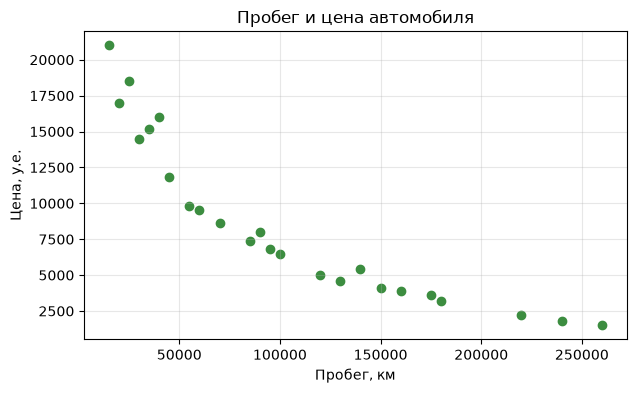

In [13]:
plt.figure(figsize=(7, 4))
plt.scatter(cars["car_mileage"], cars["car_price"], color="#3c8d40")
plt.xlabel("Пробег, км")
plt.ylabel("Цена, у.е.")
plt.title("Пробег и цена автомобиля")
plt.grid(alpha=0.3)
plt.show()

In [14]:
Xc = cars[["car_year", "car_mileage", "car_engine"]]
yc = cars["car_price"]

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.2, random_state=42)

car_model = LinearRegression()
car_model.fit(Xc_train, yc_train)
yc_pred = car_model.predict(Xc_test)

pd.DataFrame({
    "real_price": yc_test.values,
    "predicted_price": yc_pred.round(0),
    "error": (yc_test.values - yc_pred).round(0),
})

,real_price,predicted_price,error
0,4600,3590.0,1010.0
1,9800,9621.0,179.0
2,3200,1289.0,1911.0
3,15200,15273.0,-73.0
4,8600,8717.0,-117.0


In [15]:
print(f"MAE:  {mean_absolute_error(yc_test, yc_pred):.2f}")
print(f"MSE:  {mean_squared_error(yc_test, yc_pred):.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(yc_test, yc_pred)):.2f}")
print(f"R2:   {r2_score(yc_test, yc_pred):.4f}")

print("\nКоэффициенты:")
for name, coef in zip(Xc.columns, car_model.coef_):
    print(f"  {name:<12} {coef:>12.3f}")
print(f"  intercept    {car_model.intercept_:>12.3f}")

MAE:  657.95
MSE:  944705.37
RMSE: 971.96
R2:   0.9473

Коэффициенты:
  car_year         2137.800
  car_mileage         0.082
  car_engine       3775.985
  intercept    -4316533.922


### Вывод по части 3

Модель предсказывает цену со средней ошибкой MAE в условных единицах — при
средней цене около девяти тысяч это ошибка порядка нескольких сотен, то есть
несколько процентов. Для такой простой модели результат приемлемый.

Коэффициент при годе выпуска положительный и самый большой по модулю: каждый
год новизны прибавляет к цене около двух тысяч. Объём двигателя тоже повышает
цену примерно на три с половиной тысячи за литр.

А вот коэффициент при пробеге получился **положительным**, хотя здравый смысл
требует обратного: чем больше пробег, тем дешевле машина. Это не ошибка данных,
а мультиколлинеарность. Год выпуска и пробег сильно связаны между собой: свежие
машины почти всегда имеют меньший пробег. Когда оба признака стоят в модели
одновременно, год забирает на себя объяснение возраста, а пробегу достаётся
остаток, и его знак перестаёт отражать реальную зависимость.

Проверить это легко: ниже обучена модель на одном только пробеге, и там
коэффициент отрицательный, как и ожидается.

Ограничения те же, что и в части 2: данные придуманы, зависимость заложена почти
линейной, марка и состояние автомобиля не учтены вовсе. На настоящем рынке цена
зависит от бренда сильнее, чем от объёма двигателя, и линейная модель такую связь
не поймает без категориальных признаков.

In [16]:
mileage_only = LinearRegression().fit(cars[["car_mileage"]], cars["car_price"])
corr = cars["car_year"].corr(cars["car_mileage"])

print(f"Коэффициент при пробеге в одиночной модели: {mileage_only.coef_[0]:.4f}")
print(f"Корреляция года выпуска и пробега:          {corr:.3f}")

Коэффициент при пробеге в одиночной модели: -0.0708
Корреляция года выпуска и пробега:          -0.987
